### Customer Churn Prediction
**Goal:** Predict which telecom customers will leave (churn), identify the main reasons, and recommend strategies to reduce churn.

**Dataset:** Telco Customer Churn (Kaggle/IBM): 7,043 customers, 21 columns. Target: Churn (Yes/No).

**Approach**
1. Clean data and explore churn patterns
2. Train Logistic Regression and Random Forest
3. Use feature selection to test whether fewer features perform just as well
4. Evaluate with recall, precision, F1 and ROC-AUC against a baseline
5. Translate results into business recommendations

In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             recall_score, precision_score, f1_score,
                             roc_auc_score, RocCurveDisplay, precision_recall_curve)

In [133]:
# Data Loading and Preprocessing

customers = pd.read_csv('Telco-Customer-Churn.csv')

# Check types of columns
print(customers.info()) # Total Charges wrong type, needs change
customers.head()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [134]:
print(f" Missing values: {customers.isnull().sum().sum()}")
print(f" Duplicated rows: {customers.duplicated().sum()}")

 Missing values: 0
 Duplicated rows: 0


In [135]:
# Set customerID as index, not a feature for prediction
customers = customers.set_index('customerID')  

In [136]:
 # Convert TotalCharges to numeric
customers['TotalCharges'] = pd.to_numeric(customers['TotalCharges'], errors='coerce') 

# Checking whether NaN TotalCharges are associated with 0 tenure
missing = customers["TotalCharges"].isna()
customers.loc[missing, ["tenure", "MonthlyCharges", "TotalCharges"]]


,tenure,MonthlyCharges,TotalCharges
customerID,,,
4472-LVYGI,0,52.55,NaN
3115-CZMZD,0,20.25,NaN
5709-LVOEQ,0,80.85,NaN
4367-NUYAO,0,25.75,NaN
1371-DWPAZ,0,56.05,NaN
7644-OMVMY,0,19.85,NaN
3213-VVOLG,0,25.35,NaN
2520-SGTTA,0,20.00,NaN
2923-ARZLG,0,19.70,NaN


In [137]:
# Replacing NaN TotalCharges with 0, since  associated with 0 tenure
customers.loc[missing, "TotalCharges"] = 0

In [138]:
# Print the categories for text columns with more than 2 options
for col in customers.select_dtypes(include="str").columns:
    if customers[col].nunique() > 2:
        print(col, customers[col].unique())

MultipleLines <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
PaymentMethod <ArrowStringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


Categories are clean, with no typos. We are keeping “No internet service” and “No phone service” as separate categories to preserve the difference between declining a service and not having internet or phone at all.

In [139]:
# Convert Churn (target) column to 1/0 for modeling
customers['Churn'] = customers['Churn'].map({'No': 0, 'Yes': 1})
print(f"Churn rate {customers['Churn'].mean():.2%}")

Churn rate 26.54%


About 26% of customers churn, so most customers stay. Accuracy can be misleading here, so we focus on recall (catching customers who leave).

### Exploratory Analysis
Looking at:
- Does contract type affect customers likeliness of leaving?
- Do customers with shorter tenure churn more often?
- Are higher monthly charges linked to more churn?
- Does having tech support reduce churn?

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


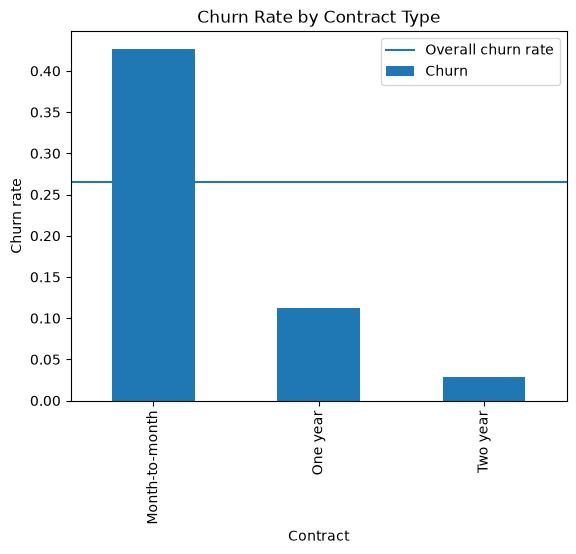

In [147]:
# Churn rate by contract type
churn_by_contract = customers.groupby('Contract')['Churn'].mean()
print(churn_by_contract)

# Plotting churn rate by contract type
churn_by_contract.plot(kind="bar")
plt.axhline(customers["Churn"].mean(), label="Overall churn rate")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Contract Type")
plt.legend()
plt.show()

Month-to-month customers churn at 43%, well above the 26.5% average, while one-year (11%) and two-year (3%) customers churn far less. Month-to-month customers pull the overall churn rate up, which suggests that moving customers onto longer contracts could reduce churn.